In [10]:
import math
import random
import datetime
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import cartopy
import cartopy.crs as ccrs
import cmocean
import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gp
import regionmask

## Read metric data

Example data from `/datasets/work/af-ag2050-climate/reference/ag2050_extension_metrics_outputs/100_2025-may_cdx_cs_a-e5_h_ccam-2203_q-agcd/annRain.csv`:
- GCM: ACCESS-ESM1-5
- RCM: CCAM-v2203-SN
- Experiment: ssp126
- Bias correction method: MRNBC
- Bias correction reference: AGCD	

In [39]:
df = pd.read_csv('THItropical.csv')

In [40]:
df

,date,out,latitude,longitude
0,1960,0,86,629
1,1961,4,86,629
2,1962,0,86,629
3,1963,0,86,629
4,1964,0,86,629
...,...,...,...,...
15573707,2011,0,251,752
15573708,2012,0,251,752
15573709,2013,0,251,752
15573710,2014,0,251,752


In [41]:
df_indexed = df.set_index(['latitude', 'longitude'])

In [42]:
da_list = []
for year in df['date'].unique():
    df_year = df_indexed[df_indexed['date'] == year]
    da_year = df_year['out'].to_xarray()
    da_year['time'] = datetime.datetime(year, 7, 1)
    da_list.append(da_year)

In [43]:
def lat_index_to_value(lat_index):
    """Convert latitude index to value"""

    lat_values = np.round(np.arange(-10, -44.51, -0.05), 2)
    lat_value = lat_values[lat_index]

    return lat_value


def lon_index_to_value(lon_index):
    """Convert latitude index to value"""

    lon_values = np.round(np.arange(112, 156.26, 0.05), 2)
    lon_value = lon_values[lon_index]

    return lon_value


v_lat_index_to_value = np.vectorize(lat_index_to_value)
v_lon_index_to_value = np.vectorize(lon_index_to_value)

In [44]:
da = xr.concat(da_list, dim='time')
da['latitude'] = v_lat_index_to_value(da['latitude'])
da['longitude'] = v_lon_index_to_value(da['longitude'])

In [45]:
da = da.rename({'latitude': 'lat', 'longitude': 'lon'})

In [48]:
da.isel(time=10)

<xarray.DataArray 'out' (lat: 655, lon: 814)> Size: 4MB
array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]], shape=(655, 814))
Coordinates:
  * lat      (lat) float64 5kB -10.1 -10.15 -10.2 -10.55 ... -43.5 -43.55 -43.6
  * lon      (lon) float64 7kB 113.0 113.0 113.0 113.1 ... 153.5 153.6 153.6
    time     datetime64[ns] 8B 1970-07-01

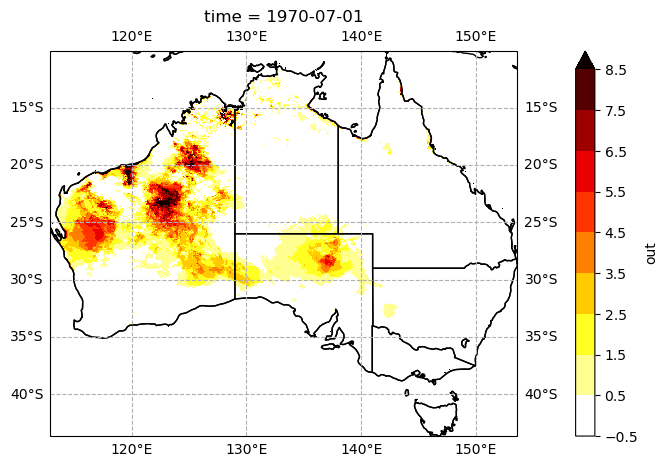

In [51]:
fig = plt.figure(figsize=[15, 5])
ax = fig.add_subplot(111, projection=ccrs.PlateCarree())
    
da.isel(time=10).plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    levels=[-0.5, 0.5, 1.5, 2.5, 3.5, 4.5, 5.5, 6.5, 7.5, 8.5],
    extend='max',
    cmap='hot_r',
#    cbar_kwargs={'label': 'total annual precipitation (mm)'},
)
ax.coastlines()
ax.add_feature(cartopy.feature.STATES)
ax.gridlines(linestyle="--", draw_labels=True)
    
plt.show()

## Spatial selection and aggregation

In [28]:
mask = wheatbelt_region.mask_3D(da)
mask = mask.squeeze()

In [29]:
da_wheatbelt = da.where(mask)

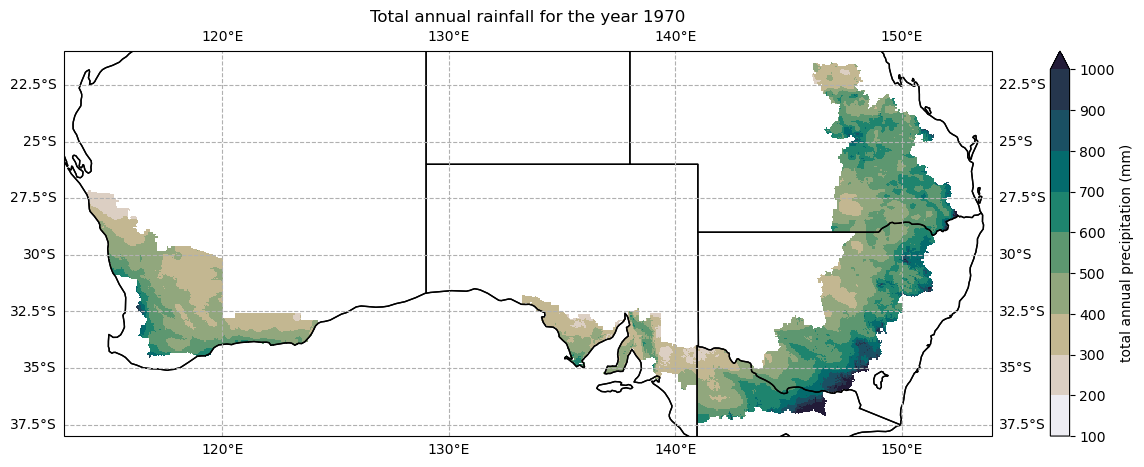

In [30]:
fig = plt.figure(figsize=[15, 5])
ax = fig.add_subplot(111, projection=ccrs.PlateCarree())
    
da_wheatbelt.isel(time=10).plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap=cmocean.cm.rain,
    levels=[100, 200, 300, 400, 500, 600, 700, 800, 900, 1000],
    extend='max',
    cbar_kwargs={'label': 'total annual precipitation (mm)'},
)
ax.coastlines()
ax.add_feature(cartopy.feature.STATES)
ax.gridlines(linestyle="--", draw_labels=True)
ax.set_extent([113, 154, -38, -21], crs=ccrs.PlateCarree())
ax.set_title('Total annual rainfall for the year 1970')
plt.show()

In [45]:
weights = np.cos(np.deg2rad(da['lat']))
da_spatial_mean = da_wheatbelt.weighted(weights).mean(dim=("lat", "lon"))

In [32]:
df_spatial_mean = da_spatial_mean.to_pandas()
df_spatial_mean.index = df_spatial_mean.index.year

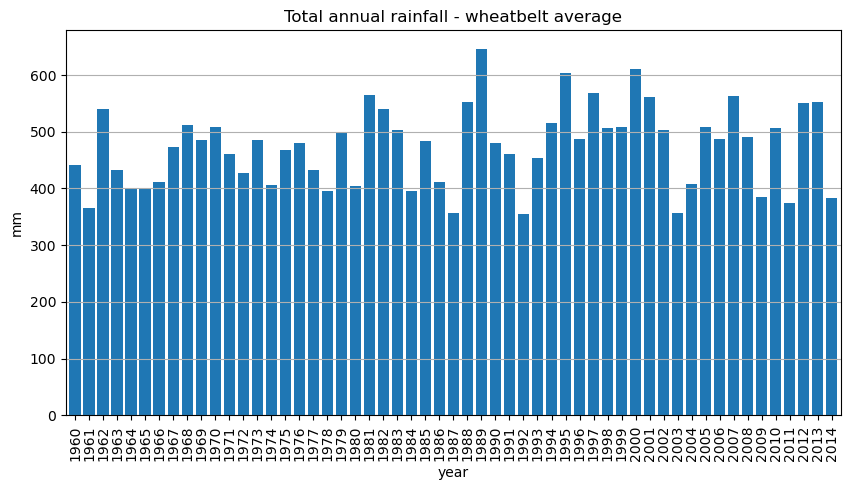

In [33]:
df_spatial_mean.plot.bar(figsize=[10, 5], width=0.8)
plt.ylabel('mm')
plt.xlabel('year')
plt.title('Total annual rainfall - wheatbelt average')
plt.grid(axis='y')
plt.show()

## Assess ensemble

Target: Plot like Figure 7 in [Narsey et al (2025)](https://connectsci.au/es/article/75/3/ES25015/252075/Disentangling-the-uncertainties-in-regional).

In [11]:
tab20 = plt.cm.tab20.colors

marker_dict = {
    'ACCESS-CM2_r2i1p1f1': (tab20[0], 'v'),
    'ACCESS-CM2_r4i1p1f1': (tab20[0], 'o'),
    'ACCESS-ESM1-5_r6i1p1f1': (tab20[1], 'o'),
    'ACCESS-ESM1-5_r20i1p1f1': (tab20[1], 'v'),
    'ACCESS-ESM1-5_r40i1p1f1': (tab20[1], '^'),
    'CESM2_r11i1p1f1': (tab20[2], 'o'),
    'CMCC-ESM2_r1i1p1f1': (tab20[3], 'o'),
    'CNRM-CM6-1-HR_r1i1p1f2': (tab20[4], 'o'),
    'CNRM-ESM2-1_r1i1p1f2': (tab20[5], 'o'),
    'EC-Earth3_r1i1p1f1': (tab20[6], 'o'),
    'EC-Earth3-Veg_r1i1p1f1': (tab20[7], 'o'),
    'FGOALS-g3_r4i1p1f1': (tab20[8], 'o'),
    'GFDL-ESM4_r1i1p1f1': (tab20[9], 'o'),
    'GISS-E2-1-G_r2i1p1f2': (tab20[10], 'o'),
    'MPI-ESM1-2-HR_r1i1p1f1': (tab20[12], 'o'),
    'MPI-ESM1-2-LR_r9i1p1f1': (tab20[13], 'o'),
    'MRI-ESM2-0_r1i1p1f1': (tab20[14], 'o'),
    'NorESM2-MM_r1i1p1f1': (tab20[15], 'o'),
    'UKESM1-0-LL_r1i1p1f2': (tab20[16], 'o'),
}

In [12]:
def metric_raw(infile, metric, bc, exp):
    """Process a metric file"""
    
    ds = xr.open_dataset(infile)
    
    da_baseline = ds[metric].sel(time=slice('1995-01-01', '2014-12-31')).mean('time', keep_attrs=True)
    if 'qdc' in infile:
        if 'AGCD' in bc:
            da_baseline = da_baseline.sel({'experiment': exp, 'obs': 'AGCD'})
        elif 'BARRA' in bc:
            da_baseline = da_baseline.sel({'experiment': exp, 'obs': 'BARRA-R2'})
    else:
        da_baseline = da_baseline.sel({'experiment': exp, 'bc': bc})
    
    da_future = ds[metric].sel(time=slice('2080-01-01', '2099-12-31')).mean('time', keep_attrs=True)
    if 'qdc' in infile:
        if 'AGCD' in bc:
            da_future = da_future.sel({'experiment': exp, 'obs': 'AGCD'})
        elif 'BARRA' in bc:
            da_future = da_future.sel({'experiment': exp, 'obs': 'BARRA-R2'})
    else:
        da_future = da_future.sel({'experiment': exp, 'bc': bc})
    
    return da_baseline, da_future


def metric_change(infile, metric, bc, exp, pct=False):
    """Process a metric file"""
    
    da_baseline, da_future = metric_raw(infile, metric, bc, exp)
    da_change = da_future - da_baseline
    if pct:
        da_change = (da_change / da_baseline) * 100
    
    return da_change

In [13]:
units_dict = {
    'THItropical': 'days per year',
    'croppingFS': 't/ha'
}

In [14]:
def plot_values(metric, region, bc, exp, ylim=[], savefig=False):
    """Plot values"""

    ensfile = {
        f'data/{metric}_bar_{region}.nc': 1,
        f'data/{metric}_ccam-2203_{region}.nc': 2,
        f'data/{metric}_nar-r3_{region}.nc': 2.9,
        f'data/{metric}_nar-r5_{region}.nc': 3.1,
        f'data/{metric}_ccam-2105_{region}.nc': 4,
        f'data/{metric}_ccam-2105-r6_{region}.nc': 4,
        f'data/{metric}_ccam-2112_{region}.nc': 4,
        f'data/{metric}_ccamo-2112_{region}.nc': 4,
        f'data/{metric}_ccamo-2112-r2_{region}.nc': 4,
        f'data/{metric}_ccamo-2112-r4_{region}.nc': 4,
        f'data/{metric}_qdc_{region}.nc': 5,
    } 

    fig = plt.figure(figsize=(10, 5))
    ax1 = plt.subplot(121)
    ax2 = plt.subplot(122)
    
    label_list = []
    baseline_values_dict = {1: [], 2: [], 2.9: [], 3.1: [], 4: [], 5: []}
    future_values_dict = {1: [], 2: [], 2.9: [], 3.1: [], 4: [], 5: []}
    for infile, index in ensfile.items():
        da_baseline, da_future = metric_raw(infile, metric, bc, exp)
        for gcm in da_baseline['gcm'].values:
            baseline_value = float(da_baseline.sel({'gcm': gcm}).values)
            future_value = float(da_future.sel({'gcm': gcm}).values)
            if math.isnan(baseline_value) or math.isnan(future_value):
                continue
            color, marker = marker_dict[gcm]
            label = gcm.replace('_' , ' ') if not gcm in label_list else None
            label_list.append(gcm)
            jitter = random.uniform(-0.05, 0.05)
            ax1.plot(index + jitter, baseline_value, marker=marker, color=color, label=label, linestyle='none')
            ax2.plot(index + jitter, future_value, marker=marker, color=color, label=label, linestyle='none')
            baseline_values_dict[index].append(baseline_value)
            future_values_dict[index].append(future_value)
    
    for index in list(set(list(ensfile.values()))):
        inst_min = np.nanmin(np.array(baseline_values_dict[index]))
        inst_max = np.nanmax(np.array(baseline_values_dict[index]))
        ax1.plot([index, index], [inst_min, inst_max], color='black', linewidth=0.5, marker='_', zorder=0)
    
    for index in list(set(list(ensfile.values()))):
        inst_min = np.nanmin(np.array(future_values_dict[index]))
        inst_max = np.nanmax(np.array(future_values_dict[index]))
        ax2.plot([index, index], [inst_min, inst_max], color='black', linewidth=0.5, marker='_', zorder=0)
    
    handles, labels = ax2.get_legend_handles_labels()
    labels, handles = zip(*sorted(zip(labels, handles), key=lambda t: t[0]))
    ax2.legend(handles, labels, bbox_to_anchor=(1.8, 0.5), loc=7)
    units = units_dict[metric]
    ax1.set_ylabel(units)
    ax2.set_ylabel(units)
    ax1.set_xticks([1, 2, 3, 4, 5], labels=['BOM', 'CSIRO', 'NSW Gov', 'UQ-DEC', 'QDC'])
    ax2.set_xticks([1, 2, 3, 4, 5], labels=['BOM', 'CSIRO', 'NSW Gov', 'UQ-DEC', 'QDC'])
    ax1.set_title(f'{metric}, 1995-2014 (ssp370)')
    ax2.set_title(f'{metric}, 2080-2099 (ssp370)')
    if ylim:
        ax1.set_ylim(ylim)
        ax2.set_ylim(ylim)
    
    if savefig:
        outfile = f'{metric}-values_{region}_{bc}_{exp}.png'
        plt.savefig(outfile, bbox_inches='tight', facecolor='white', dpi=300)
        print(outfile)
    plt.show()

In [15]:
def plot_change(metric, region, bc, exp, pct=False, savefig=False):
    """Plot change"""

    ensfile = {
        f'data/{metric}_bar_{region}.nc': 1,
        f'data/{metric}_ccam-2203_{region}.nc': 2,
        f'data/{metric}_nar-r3_{region}.nc': 2.9,
        f'data/{metric}_nar-r5_{region}.nc': 3.1,
        f'data/{metric}_ccam-2105_{region}.nc': 4,
        f'data/{metric}_ccam-2105-r6_{region}.nc': 4,
        f'data/{metric}_ccam-2112_{region}.nc': 4,
        f'data/{metric}_ccamo-2112_{region}.nc': 4,
        f'data/{metric}_ccamo-2112-r2_{region}.nc': 4,
        f'data/{metric}_ccamo-2112-r4_{region}.nc': 4,
        f'data/{metric}_qdc_{region}.nc': 5,
    } 
    
    fig = plt.figure(figsize=(5, 5))
    ax1 = plt.subplot(111)
    
    label_list = []
    change_values_dict = {1: [], 2: [], 2.9: [], 3.1: [], 4: [], 5: []}
    for infile, index in ensfile.items():
        da_change = metric_change(infile, metric, bc, exp, pct=pct)
        for gcm in da_change['gcm'].values:
            change_value = float(da_change.sel({'gcm': gcm}).values)
            if math.isnan(change_value):
                continue
            color, marker = marker_dict[gcm]
            label = gcm.replace('_' , ' ') if not gcm in label_list else None
            label_list.append(gcm)
            jitter = random.uniform(-0.05, 0.05)
            ax1.plot(index + jitter, change_value, marker=marker, color=color, label=label, linestyle='none')
            change_values_dict[index].append(change_value)
    
    for index in list(set(list(ensfile.values()))):
        inst_min = np.nanmin(np.array(change_values_dict[index]))
        inst_max = np.nanmax(np.array(change_values_dict[index]))
        ax1.plot([index, index], [inst_min, inst_max], color='black', linewidth=0.5, marker='_', zorder=0)
    
    handles, labels = ax1.get_legend_handles_labels()
    labels, handles = zip(*sorted(zip(labels, handles), key=lambda t: t[0]))
    ax1.legend(handles, labels, bbox_to_anchor=(1.7, 0.5), loc=7)
    units = '%' if pct else units_dict[metric]
    ax1.set_ylabel(units)
    ax1.axhline(y=0, linestyle=':', color='0.5')
    ax1.set_xticks([1, 2, 3, 4, 5], labels=['BOM', 'CSIRO', 'NSW Gov', 'UQ-DEC', 'QDC'])
    ax1.set_title(f'Change in {metric}, 1995-2014 to 2080-2099 ({exp})')

    if savefig:
        end = '_pct.png' if pct else '.png'
        outfile = f'{metric}-change_{region}_{bc}_{exp}{end}'
        plt.savefig(outfile, bbox_inches='tight', facecolor='white', dpi=300)
        print(outfile)
    plt.show()

THItropical-values_mod-ncra-nth_v1-r1-ACS-QME-BARRAR2-1980-2022_ssp370.png


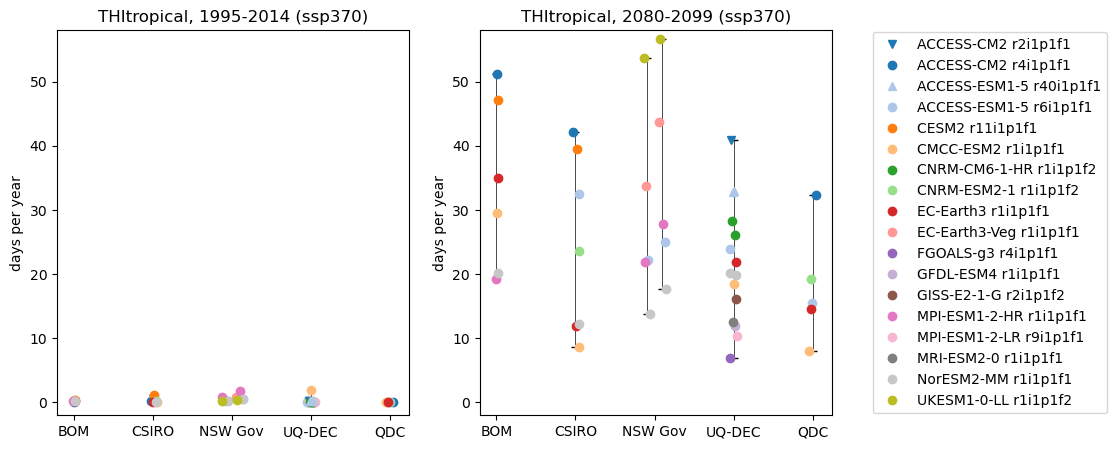

In [16]:
plot_values('THItropical', 'mod-ncra-nth', 'v1-r1-ACS-QME-BARRAR2-1980-2022', 'ssp370', ylim=[-2, 58], savefig=True)

THItropical-change_mod-ncra-nth_v1-r1-ACS-QME-BARRAR2-1980-2022_ssp370.png


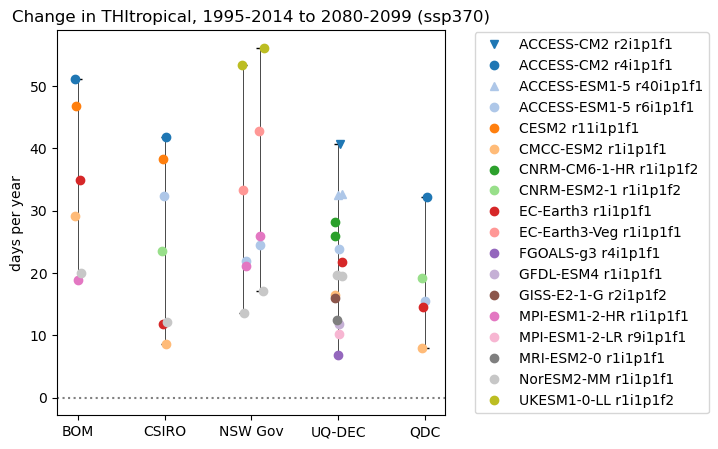

In [17]:
plot_change('THItropical', 'mod-ncra-nth', 'v1-r1-ACS-QME-BARRAR2-1980-2022', 'ssp370', savefig=True)

croppingFS-values_cropping_v1-r1-ACS-QME-BARRAR2-1980-2022_ssp370.png


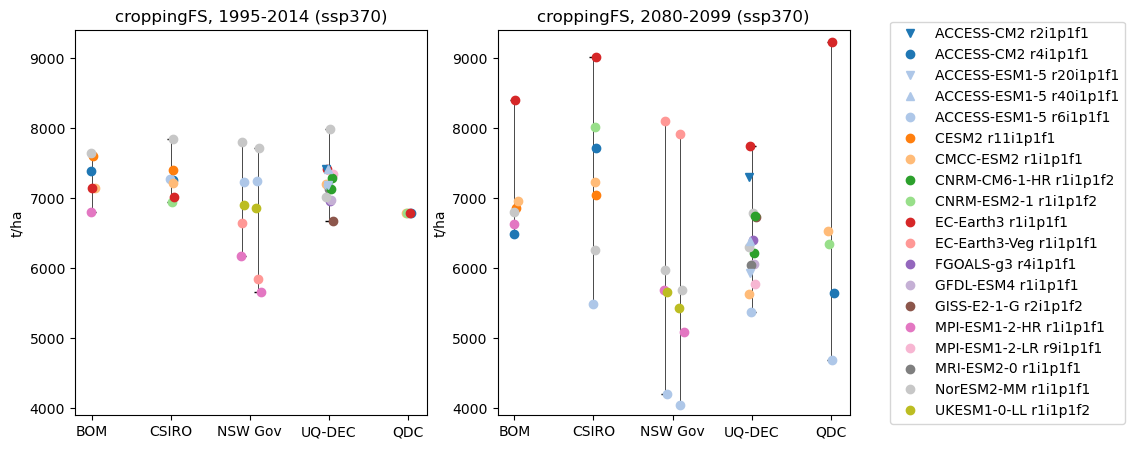

In [18]:
plot_values('croppingFS', 'cropping', 'v1-r1-ACS-QME-BARRAR2-1980-2022', 'ssp370', ylim=[3900, 9400], savefig=True)

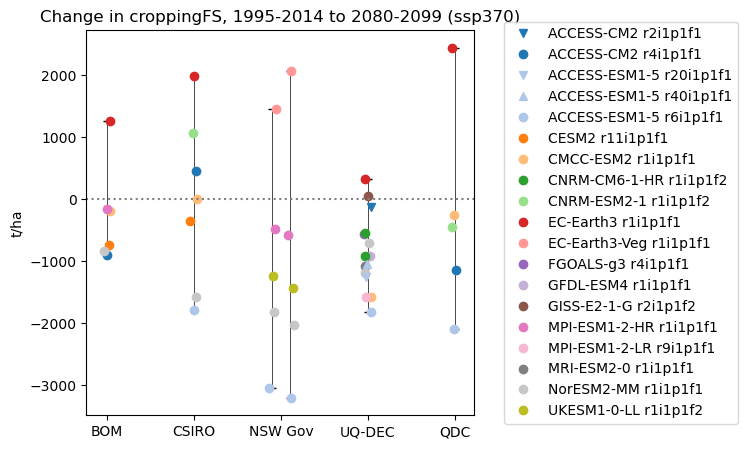

In [19]:
plot_change('croppingFS', 'cropping', 'v1-r1-ACS-QME-BARRAR2-1980-2022', 'ssp370', pct=False, savefig=False)

croppingFS-change_cropping_v1-r1-ACS-QME-BARRAR2-1980-2022_ssp370_pct.png


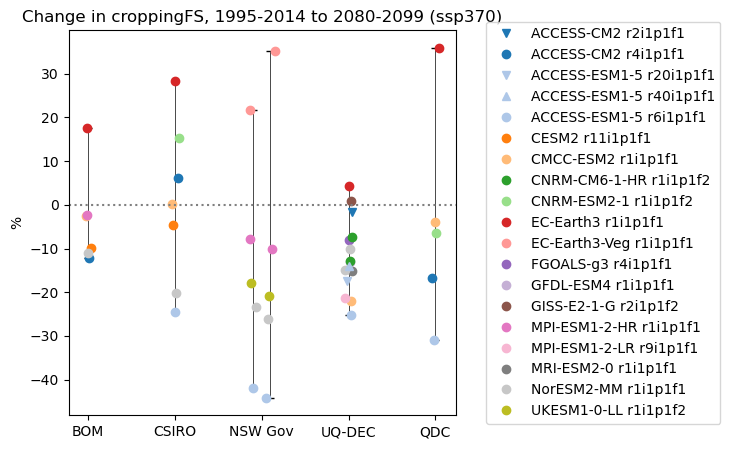

In [20]:
plot_change('croppingFS', 'cropping', 'v1-r1-ACS-QME-BARRAR2-1980-2022', 'ssp370', pct=True, savefig=True)